# Analyse des livres de books.toscrape.com

Site d'entraînement au scraping (1000 livres, 50 pages). Le site est statique : `requests` + Beautiful Soup suffisent, sans Selenium.

1. **Collecte** : URLs puis fiches, avec délai, retry, reprise après interruption et vérification de `robots.txt`
2. **Nettoyage à la source** : types corrects, prix converti avec le taux du jour
3. **Validation** : contrôles de qualité
4. **Export** : CSV, Parquet, SQLite
5. **Analyse** : catégories, prix, notes, stock

In [1]:
import sys

sys.path.append("../src")

import matplotlib.pyplot as plt
import pandas as pd

from webscraping.books import add_euro_prices, scrape_books
from webscraping.fx import get_gbp_eur
from webscraping.plotting import INK, MUTED, SERIES, apply_style
from webscraping.storage import save_dataset
from webscraping.validation import validate_books

apply_style()

## 1. Collecte

In [2]:
import time

debut = time.perf_counter()
# Le fichier de reprise permet de relancer la cellule après une interruption
brut = scrape_books(checkpoint="../data/livres_partiel.csv", delay=0.3)
print(f"Durée : {time.perf_counter() - debut:.0f} s")
brut.head()

Reprise : 1000 livres déjà enregistrés


1000 URLs collectées
1000 lignes enregistrées, 0 erreurs
Durée : 29 s


,url,categorie,titre,prix_gbp,stock,note,description,upc,date_collecte
0,https://books.toscrape.com/catalogue/a-light-i...,Poetry,A Light in the Attic,51.77,22,3,It's hard to imagine a world without A Light i...,a897fe39b1053632,2026-11-17
1,https://books.toscrape.com/catalogue/tipping-t...,Historical Fiction,Tipping the Velvet,53.74,20,1,"""Erotic and absorbing...Written with starling ...",90fa61229261140a,2026-11-17
2,https://books.toscrape.com/catalogue/soumissio...,Fiction,Soumission,50.10,20,1,"Dans une France assez proche de la nôtre, un h...",6957f44c3847a760,2026-11-17
3,https://books.toscrape.com/catalogue/sharp-obj...,Mystery,Sharp Objects,47.82,20,4,"WICKED above her hipbone, GIRL across her hear...",e00eb4fd7b871a48,2026-11-17
4,https://books.toscrape.com/catalogue/sapiens-a...,History,Sapiens: A Brief History of Humankind,54.23,20,5,From a renowned historian comes a groundbreaki...,4165285e1663650f,2026-11-17


## 2. Nettoyage à la source

Les types sont déjà corrects (prix et stock numériques, note de 1 à 5, description vide si absente). Il reste à convertir les prix.

In [3]:
taux = get_gbp_eur()
print(f"1 GBP = {taux.rate} EUR (source : {taux.source}, date du taux : {taux.date})")

livres = add_euro_prices(brut, taux.rate)
livres.dtypes

1 GBP = 1.1983 EUR (source : frankfurter, date du taux : 2026-11-16)


url                  str
categorie            str
titre                str
prix_gbp         float64
stock              int64
note               int64
description          str
upc                  str
date_collecte        str
taux_gbp_eur     float64
prix_eur         float64
dtype: object

## 3. Validation

In [4]:
problemes = validate_books(livres, expected_rows=1000)
print("Aucun problème détecté" if not problemes else "\n".join(problemes))
livres.isna().sum()  # seule la description peut être vide

Aucun problème détecté


url              0
categorie        0
titre            0
prix_gbp         0
stock            0
note             0
description      2
upc              0
date_collecte    0
taux_gbp_eur     0
prix_eur         0
dtype: int64

## 4. Export

CSV pour l'échange, Parquet pour les gros volumes (typage conservé), SQLite pour interroger en SQL.

In [5]:
save_dataset(livres, "livres", "../data")

[WindowsPath('../data/livres.csv'),
 WindowsPath('../data/livres.parquet'),
 WindowsPath('../data/livres.sqlite')]

## 5. Analyse

"Default" et "Add a comment" sont de vraies catégories du site : elles regroupent des livres sans vraie catégorie. On les rassemble sous "Sans catégorie" pour ne pas fausser l'analyse par catégorie.

In [6]:
livres["categorie_analyse"] = livres["categorie"].replace(
    {"Default": "Sans catégorie", "Add a comment": "Sans catégorie"}
)

par_categorie = (
    livres.groupby("categorie_analyse")
    .agg(livres=("titre", "count"), prix_moyen_eur=("prix_eur", "mean"), note_moyenne=("note", "mean"), stock_total=("stock", "sum"))
    .round(2)
    .sort_values("livres", ascending=False)
)
par_categorie.head(12)

,livres,prix_moyen_eur,note_moyenne,stock_total
categorie_analyse,,,,
Sans catégorie,219,41.73,2.81,1861
Nonfiction,110,41.05,2.88,975
Sequential Art,75,41.43,2.97,686
Fiction,65,43.22,3.18,588
Young Adult,54,42.48,3.30,464
Fantasy,48,47.44,3.08,372
Romance,35,40.66,2.63,269
Mystery,32,38.01,2.94,290
Food and Drink,30,37.64,2.90,319


### Catégories les plus fournies

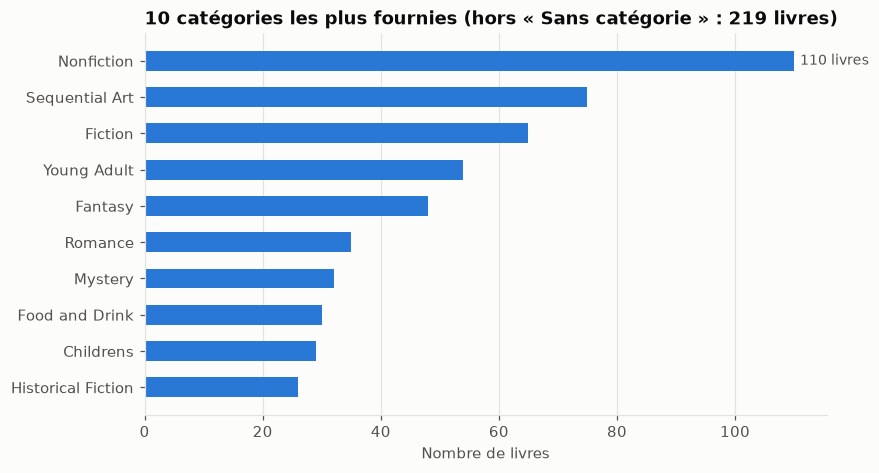

In [7]:
vraies = livres[livres["categorie_analyse"] != "Sans catégorie"]
sans = len(livres) - len(vraies)
top = vraies["categorie"].value_counts().head(10).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top.index, top.values, height=0.55, color=SERIES)
ax.text(top.values[-1] + 1, len(top) - 1, f"{top.values[-1]} livres", va="center", color=MUTED, fontsize=9)  # étiquette sur la plus grande barre seulement
ax.set_title(f"10 catégories les plus fournies (hors « Sans catégorie » : {sans} livres)")
ax.set_xlabel("Nombre de livres")
ax.grid(axis="y", visible=False)
plt.show()

### Distribution des prix

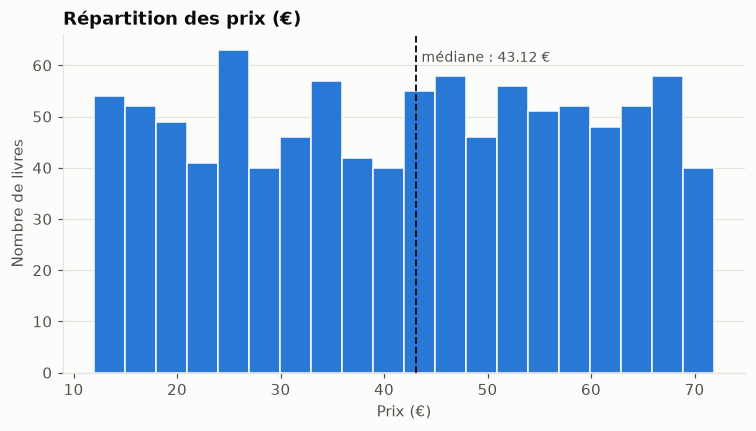

In [8]:
mediane = livres["prix_eur"].median()

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(livres["prix_eur"], bins=20, color=SERIES, edgecolor="#fcfcfb", linewidth=1)
ax.axvline(mediane, color=INK, linewidth=1.2, linestyle="--")
ax.text(mediane + 0.5, ax.get_ylim()[1] * 0.95, f"médiane : {mediane:.2f} €", color=MUTED, fontsize=9, va="top")
ax.set_title("Répartition des prix (€)")
ax.set_xlabel("Prix (€)")
ax.set_ylabel("Nombre de livres")
ax.grid(axis="x", visible=False)
plt.show()

### Le prix dépend-il de la note ?

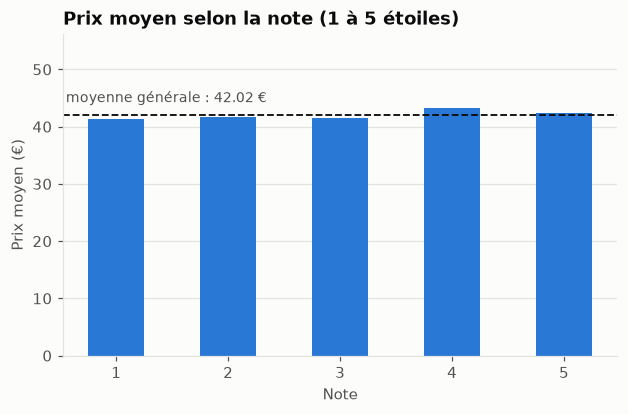

Corrélation note / prix : 0.028


In [9]:
prix_par_note = livres.groupby("note")["prix_eur"].mean()
moyenne = livres["prix_eur"].mean()

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.bar(prix_par_note.index, prix_par_note.values, width=0.5, color=SERIES)
ax.axhline(moyenne, color=INK, linewidth=1.2, linestyle="--")
ax.set_ylim(0, prix_par_note.max() * 1.3)  # laisse la place à l'étiquette au-dessus des barres
ax.text(0.55, moyenne * 1.04, f"moyenne générale : {moyenne:.2f} €", color=MUTED, fontsize=9, va="bottom", ha="left")
ax.set_title("Prix moyen selon la note (1 à 5 étoiles)")
ax.set_xlabel("Note")
ax.set_ylabel("Prix moyen (€)")
ax.grid(axis="x", visible=False)
plt.show()
print(f"Corrélation note / prix : {livres['note'].corr(livres['prix_eur']):.3f}")

### Livres presque en rupture

In [10]:
rupture = livres[livres["stock"] <= 2]
print(f"{len(rupture)} livres ({len(rupture) / len(livres):.0%}) ont 2 exemplaires ou moins en stock")
rupture[["titre", "categorie", "prix_eur", "stock"]].sort_values("prix_eur", ascending=False).head(10)

112 livres (11%) ont 2 exemplaires ou moins en stock


,titre,categorie,prix_eur,stock
971,Listen to Me (Fusion #1),Romance,70.69,1
964,Myriad (Prentor #1),Fantasy,70.40,1
948,Shameless,New Adult,69.92,1
910,Travels with Charley: In Search of America,Nonfiction,69.29,1
924,The No. 1 Ladies' Detective Agency (No. 1 Ladi...,Mystery,69.14,1
940,The Bhagavad Gita,Religion,68.89,1
898,H is for Hawk,Nonfiction,68.81,2
972,Kitchens of the Great Midwest,Fiction,68.54,1
996,"Ajin: Demi-Human, Volume 1 (Ajin: Demi-Human #1)",Sequential Art,68.37,1
978,"Giant Days, Vol. 1 (Giant Days #1-4)",Sequential Art,68.02,1
